## Survey Data Risk Stratification - Predicting Mental Health Risk Levels Using Machine Learning

### Problem Statement:

The aim is to build a screening tool that helps flag employees who may be at higher risk of mental health challenges, based on their workplace survey responses. The goal isn’t to diagnose or replace professional judgment, but to surface cases that deserve closer human review.

The survey captures factors like mental health history, workplace culture, and treatment‑seeking behavior. Using this data, we’ll train machine learning models to classify employees into lower‑risk and higher‑risk groups.

To explore what works best, we’ll compare simple baseline models (Logistic Regression, SVM, KNN, Naive Bayes, MLP) against more powerful ensemble methods (Random Forest, Extra Trees, AdaBoost, Gradient Boosting, XGBoost). Because self‑report data has natural limits, we won’t focus on raw accuracy. Instead, we’ll judge models by their macro‑F1 score and especially their recall on the High‑risk class—since the real value lies in catching as many potential high‑risk cases as possible for timely follow‑up.


### Data Dictionary (Columns)

- **Timestamp**: Date and time when the survey response was recorded  
- **Age**: Age of the respondent  
- **Gender**: Gender identity of the respondent (Male, Female, Other)  
- **Country**: Country of residence  
- **state**: State/region within the country  
- **self_employed**: Whether the respondent is self‑employed (Yes/No/NA)  
- **family_history**: Family history of mental illness (Yes/No)  
- **treatment**: Whether the respondent has sought treatment for mental health (Yes/No)  
- **work_interfere**: Frequency of mental health interfering with work (Never, Rarely, Often)  
- **no_employees**: Size of the company by number of employees (e.g., 1‑5, 6‑25, >1000)  
- **remote_work**: Whether the respondent works remotely (Yes/No)  
- **tech_company**: Whether the respondent works in a tech company (Yes/No)  
- **benefits**: Availability of mental health benefits at workplace (Yes/No/Don't know)  
- **care_options**: Awareness of care options provided by employer  
- **wellness_program**: Availability of wellness programs at workplace (Yes/No)  
- **seek_help**: Encouragement from employer to seek help (Yes/No)  
- **anonymity**: Whether anonymity is protected when seeking help (Yes/No)  
- **leave**: Ease of taking medical leave for mental health (Very easy, Somewhat easy, Difficult, NA)  
- **mental_health_consequence**: Perceived consequences of discussing mental health at work  
- **phys_health_consequence**: Perceived consequences of discussing physical health at work  
- **coworkers**: Comfort level discussing mental health with coworkers  
- **supervisor**: Comfort level discussing mental health with supervisor  
- **mental_health_interview**: Willingness to discuss mental health in a job interview  
- **phys_health_interview**: Willingness to discuss physical health in a job interview  
- **mental_vs_physical**: Perception of mental health vs physical health importance  
- **obs_consequence**: Whether observed negative consequences of mental health disclosure (Yes/No)  
- **comments**: Free‑text comments from respondent  


## Table of Contents

1. Import Packages
2. Load the Dataset
3. Initial Data Cleaning
4. Engineering the Target Variable
5. Exploratory Data Analysis

   * 5.1 Statistical Summary
   * 5.2 Missing-Value Analysis
   * 5.3 Univariate Analysis – Age
   * 5.4 Univariate Analysis – Categorical Features
   * 5.5 Target-Variable Distribution
   * 5.6 Bivariate Analysis – Features vs. Risk Level
6. Feature Set and Leakage Guard
7. Train–Test Split
8. Preprocessing Pipeline
9. Base Model Building and Comparison
10. Hyperparameter Tuning
11. Final Model Selection
12. Final Evaluation on the Held-Out Test Set

    * 12.1 Classification Report
    * 12.2 Confusion Matrix
    * 12.3 ROC Curve and ROC-AUC
    * 12.4 Performance Summary
13. Feature Importance and Interpretability
14. Conclusion


### 1. Import Packages:

In [1]:
# Numerical and data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warning management
import warnings
warnings.filterwarnings('ignore')

# Model selection and validation
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score, GridSearchCV)

# Preprocessing and pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, LabelEncoder)

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier)
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve)

# Result-table formatting
from tabulate import tabulate

# Plotting configuration
plt.style.use('ggplot')

# Reproducibility
RANDOM_STATE = 150

### 2. Load the Dataset:

In [2]:
df = pd.read_csv(r"C:\Users\DELL\Downloads\Mental Health in Tech Survey Dataset.csv")

In [3]:
# Shape of dataset (no. of rows ans columns)
df.shape

(1259, 27)

In [4]:
# First five rows of dataset
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In [5]:
# Understanding the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Timestamp                  1259 non-null   object
 1   Age                        1259 non-null   int64 
 2   Gender                     1259 non-null   object
 3   Country                    1259 non-null   object
 4   state                      744 non-null    object
 5   self_employed              1241 non-null   object
 6   family_history             1259 non-null   object
 7   treatment                  1259 non-null   object
 8   work_interfere             995 non-null    object
 9   no_employees               1259 non-null   object
 10  remote_work                1259 non-null   object
 11  tech_company               1259 non-null   object
 12  benefits                   1259 non-null   object
 13  care_options               1259 non-null   object
 14  wellness

### 3. Initial Cleaning

We are doing some basic cleaning before EDA because the dataset has obvious mistakes that would block meaningful insights. This includes things like fixing text formats, making sure ages fall in a valid range and removing duplicate rows. These are simple rules that don’t depend on the data itself, so it’s safe to do them early. Anything that needs learning from the data, like filling in missing values or encoding categories, is done later inside the pipeline after the train/test split to avoid leakage.


In [6]:
df.Gender.unique()

array(['Female', 'M', 'Male', 'male', 'female', 'm', 'Male-ish', 'maile',
       'Trans-female', 'Cis Female', 'F', 'something kinda male?',
       'Cis Male', 'Woman', 'f', 'Mal', 'Male (CIS)', 'queer/she/they',
       'non-binary', 'Femake', 'woman', 'Make', 'Nah', 'All', 'Enby',
       'fluid', 'Genderqueer', 'Female ', 'Androgyne', 'Agender',
       'cis-female/femme', 'Guy (-ish) ^_^', 'male leaning androgynous',
       'Male ', 'Man', 'Trans woman', 'msle', 'Neuter', 'Female (trans)',
       'queer', 'Female (cis)', 'Mail', 'cis male', 'A little about you',
       'Malr', 'p', 'femail', 'Cis Man',
       'ostensibly male, unsure what that really means'], dtype=object)

In [7]:
df.Age.unique()

array([         37,          44,          32,          31,          33,
                35,          39,          42,          23,          29,
                36,          27,          46,          41,          34,
                30,          40,          38,          50,          24,
                18,          28,          26,          22,          19,
                25,          45,          21,         -29,          43,
                56,          60,          54,         329,          55,
       99999999999,          48,          20,          57,          58,
                47,          62,          51,          65,          49,
             -1726,           5,          53,          61,           8,
                11,          -1,          72])

In [8]:
# Standardize column names (guard against stray whitespace)
df.columns = [c.strip() for c in df.columns]

# Drop duplicate rows first, before any derived columns exist
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Clean Gender: the raw column is free text with dozens of variants
def clean_gender(g):
    if pd.isna(g):
        return np.nan
    g = str(g).strip().lower()
    male_set = {'male', 'm', 'man', 'cis male', 'cis man', 'male (cis)', 'malr',
                'mail', 'make', 'msle', 'guy (-ish) ^_^', 'male-ish', 'maile',
                'ostensibly male, unsure what that really means'}
    female_set = {'female', 'f', 'woman', 'cis female', 'cis-female/femme',
                  'female (cis)', 'femake', 'femail', 'cis woman'}
    if g in male_set:
        return 'Male'
    if g in female_set:
        return 'Female'
    return 'Other'

df['Gender_clean'] = df['Gender'].apply(clean_gender)

# Clean Age: the raw column has implausible values (negative, 3+ digit ages)
df.loc[(df['Age'] < 18) | (df['Age'] > 100), 'Age'] = np.nan

print("Gender categories after cleaning:", df['Gender_clean'].value_counts(dropna=False).to_dict())
print("\nAge range after cleaning:", df['Age'].min(), '-', df['Age'].max())
print("Age missing after cleaning:", df['Age'].isna().sum())

Duplicate rows: 0
Gender categories after cleaning: {'Male': 992, 'Female': 247, 'Other': 20}

Age range after cleaning: 18.0 - 72.0
Age missing after cleaning: 8


### 4. Engineering the Target Variable (`risk_level`)

The raw survey has no ready-made risk label, so one is engineered from four related columns:

- `work_interfere` (Never=0, Rarely=1, Sometimes=2, Often=3 - missing treated as 0, i.e. no reported interference)
- `family_history` (Yes=1, No=0)
- `treatment` (Yes=1, No=0)
- `obs_consequence` (Yes=1, No=0)

`risk_score = 2 x work_interfere_score + family_history + treatment + obs_consequence`, then split at the **median** into two balanced groups: **Low** vs **High** risk (binary).

This risk score is not clinically validated, but it uses the most logical survey variables that directly impact mental health, with work interference weighted more heavily to reflect its importance.

In [9]:
print(df.work_interfere.unique())
print(df.family_history.unique())
print(df.treatment.unique())
print(df.obs_consequence.unique())

['Often' 'Rarely' 'Never' 'Sometimes' nan]
['No' 'Yes']
['Yes' 'No']
['No' 'Yes']


In [10]:
# Converting text responses to numbers and treating missing values as 0.
interfere_map = {'Never': 0, 'Rarely': 1, 'Sometimes': 2, 'Often': 3}
work_interfere_score = df['work_interfere'].map(interfere_map).fillna(0)

yn_map = {'Yes': 1, 'No': 0}
family_history_score = df['family_history'].map(yn_map).fillna(0)
treatment_score = df['treatment'].map(yn_map).fillna(0)
obs_consequence_score = df['obs_consequence'].map(yn_map).fillna(0)

risk_score = (2 * work_interfere_score) + family_history_score + treatment_score + obs_consequence_score


# Split risk_score into balanced Low/High categories at the median, with a fallback if qcut fails

try:
    df['risk_level'] = pd.qcut(risk_score, q=2, labels=['Low', 'High'], duplicates='drop')
    assert df['risk_level'].nunique() == 2
except AssertionError:
    threshold = risk_score.median()
    df['risk_level'] = np.where(risk_score > threshold, 'High', 'Low')

print(df['risk_level'].value_counts())

risk_level
Low     696
High    563
Name: count, dtype: int64


### 5. Exploratory Data Analysis

#### 5.1 Statistical summary

In [11]:
df[['Age']].describe().round(0).astype(int)

,Age
count,1251
mean,32
std,7
min,18
25%,27
50%,31
75%,36
max,72


In [12]:
# Quick cardinality check across all categorical columns - flags anything with unexpectedly many categories 

cat_cols_all = [c for c in df.columns if c not in ['Timestamp', 'comments', 'Age', 'Gender', 'risk_level']]
pd.DataFrame({
    'n_unique': [df[c].nunique(dropna=True) for c in cat_cols_all],
    'n_missing': [df[c].isna().sum() for c in cat_cols_all]
}, index=cat_cols_all).sort_values('n_unique', ascending=False)

,n_unique,n_missing
Country,48,0
state,45,515
no_employees,6,0
leave,5,0
work_interfere,4,264
care_options,3,0
benefits,3,0
wellness_program,3,0
phys_health_interview,3,0
coworkers,3,0


#### 5.2 Missing values

In [13]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct}).query('missing_count > 0')

,missing_count,missing_pct
comments,1095,87.0
state,515,40.9
work_interfere,264,21.0
self_employed,18,1.4
Age,8,0.6


In [14]:
df.loc[df['state'].notna(), 'Country'].value_counts()

Country
United States    740
Latvia             1
Israel             1
Bahamas, The       1
Bulgaria           1
Name: count, dtype: int64

- `comments` and `state` are missing for a large share of respondents - `comments` is unstructured free text and `state` is only populated for US respondents, so both are dropped rather than imputed.
- `work_interfere` and `self_employed` have moderate missingness that's informative in itself (e.g. a missing `work_interfere` plausibly means the respondent never sought treatment) - handled explicitly rather than silently dropped.


#### 5.3 Univariate analysis - Age (numeric)

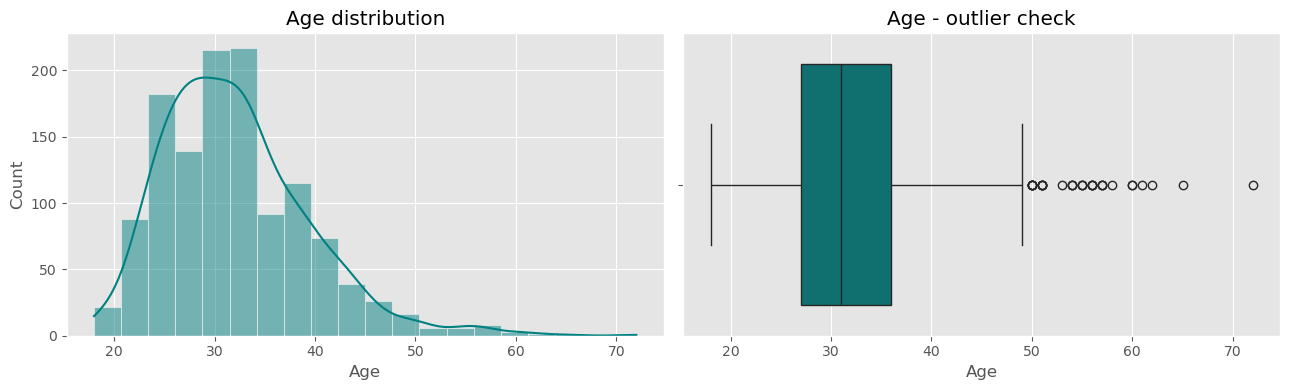

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['Age'].dropna(), kde=True, ax=axs[0], color='teal', bins=20)
axs[0].set_title('Age distribution')

sns.boxplot(x=df['Age'].dropna(), ax=axs[1], color='teal')
axs[1].set_title('Age - outlier check')
plt.tight_layout()
plt.show()

The boxplot confirms Age is well-behaved after the cleaning (implausible values already converted to missing) - no further outlier trimming is applied.

#### 5.4 Univariate analysis - categorical features (all columns)

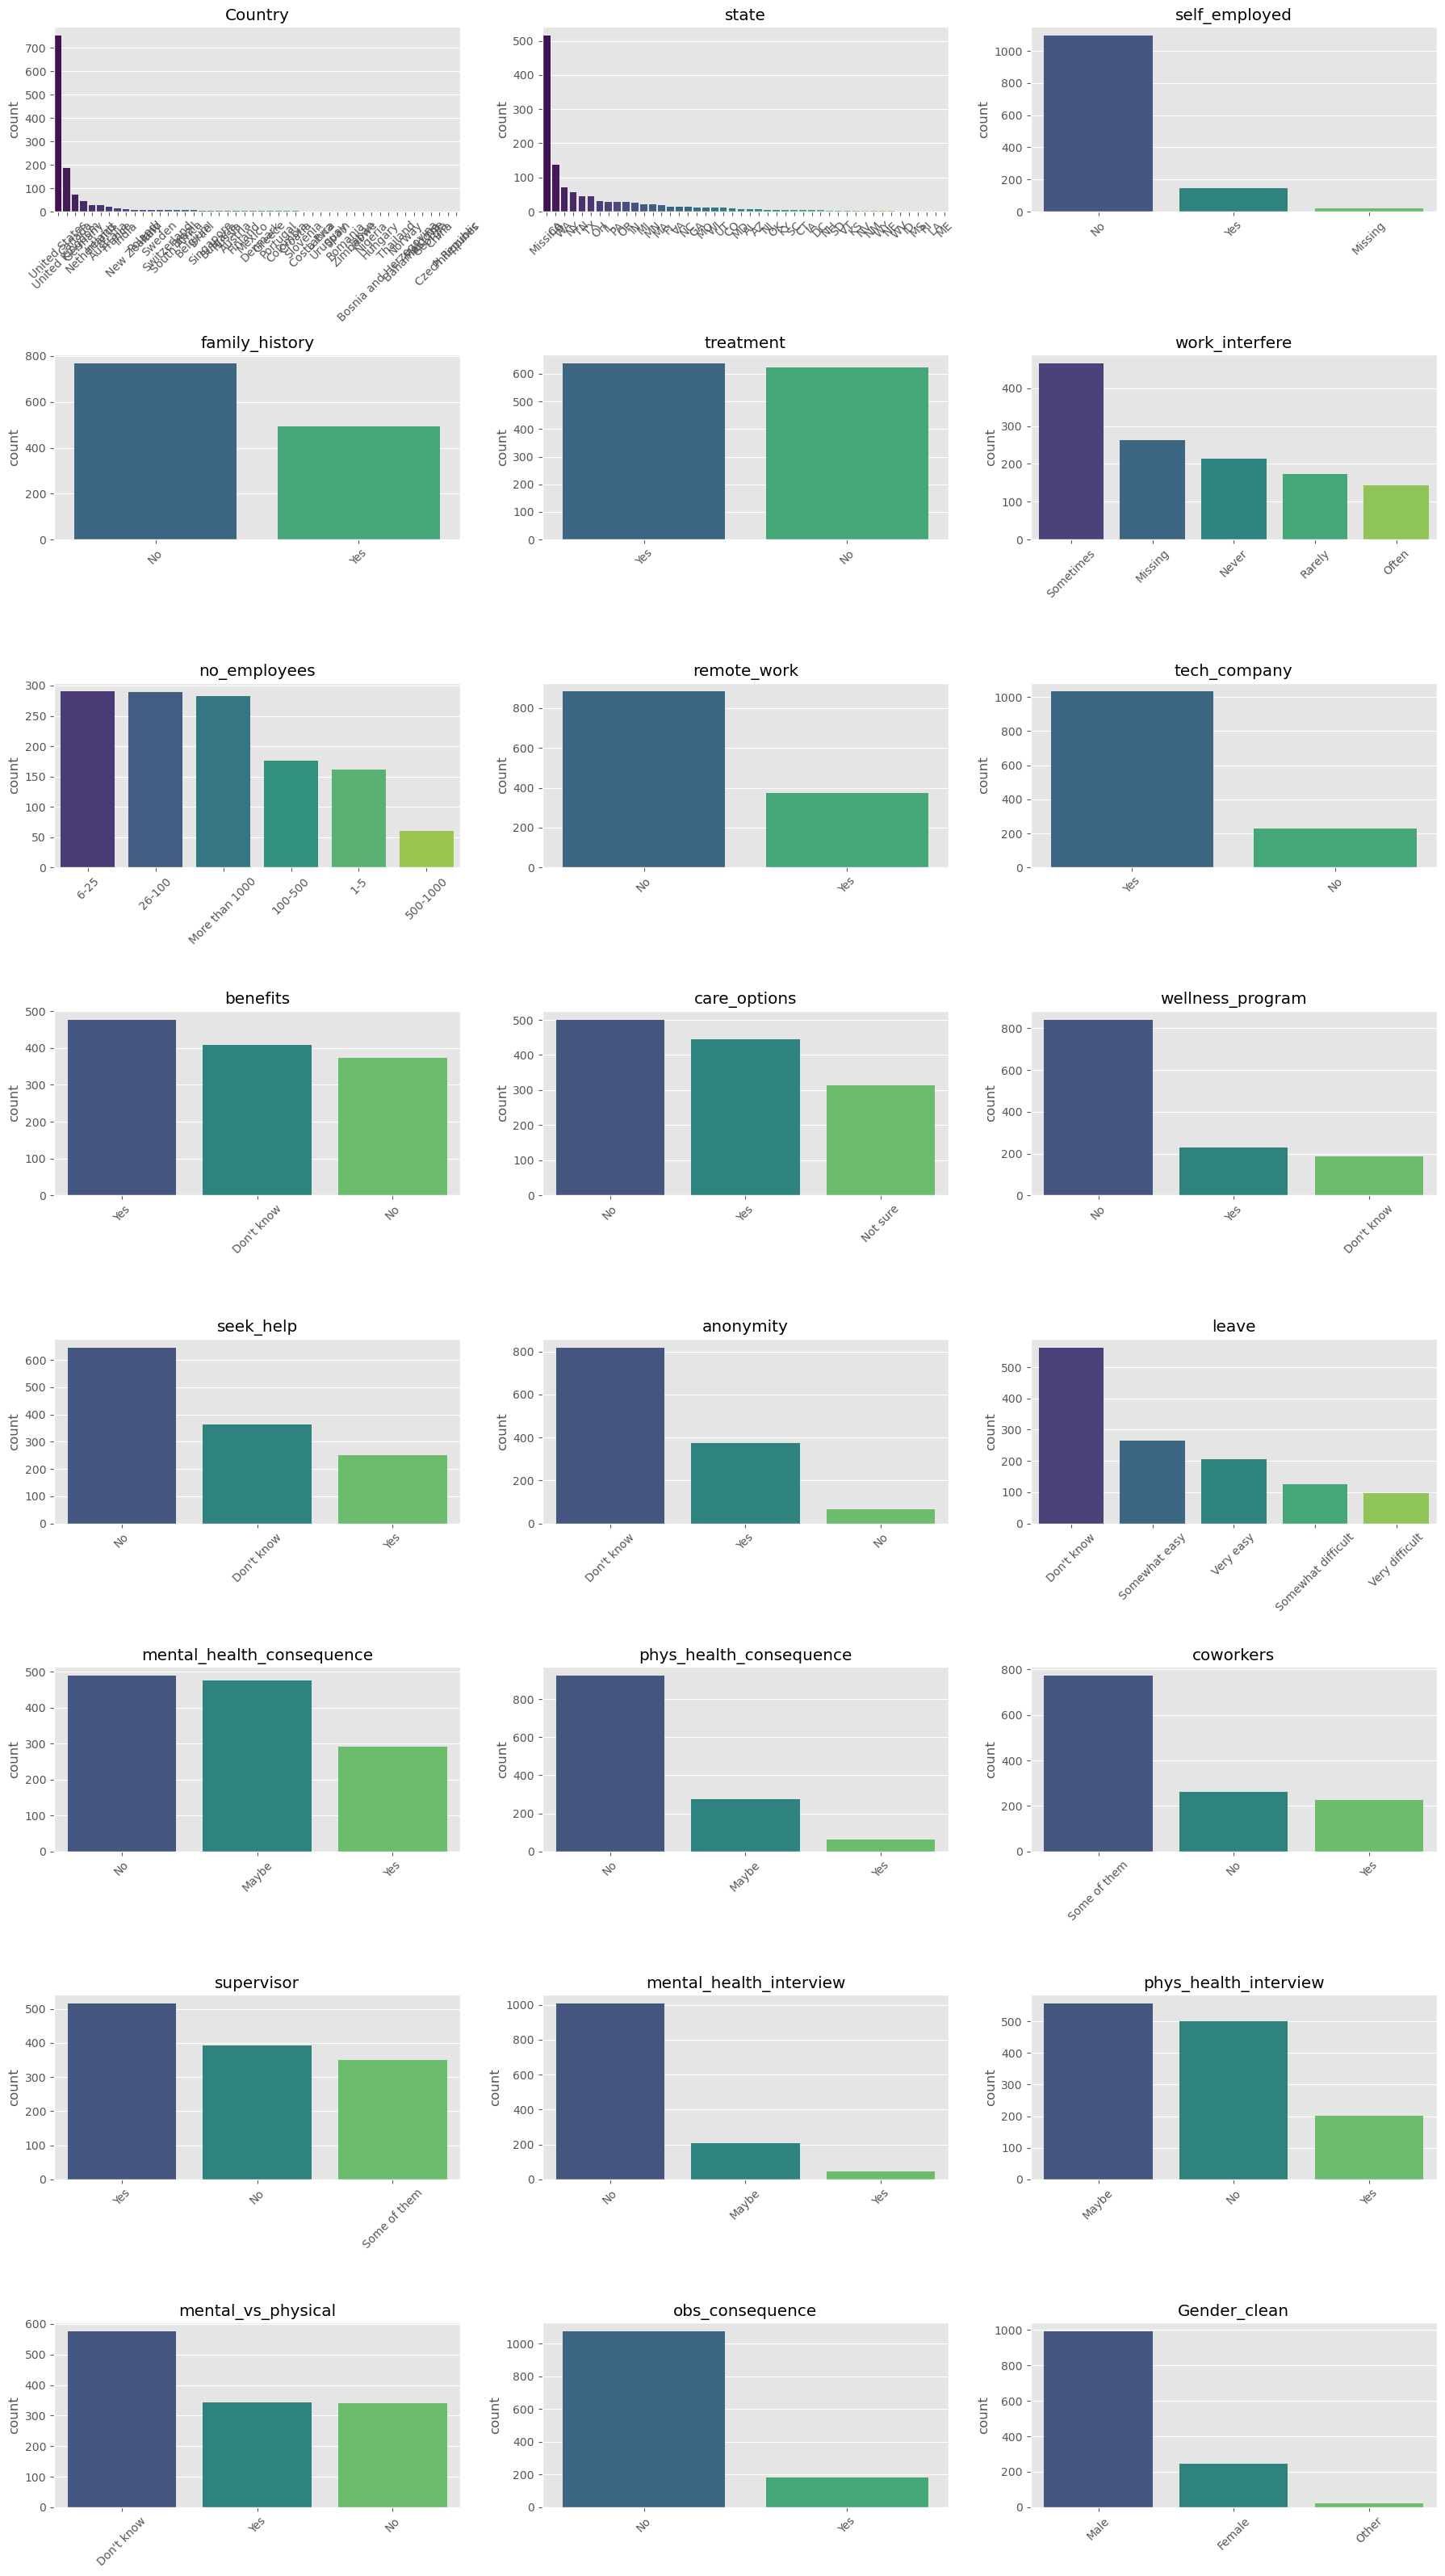

In [16]:
cat_features_to_plot = [c for c in cat_cols_all if c not in ['risk_level']]

n_cols = 3
n_rows = int(np.ceil(len(cat_features_to_plot) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axs = axs.ravel()

for ax, col in zip(axs, cat_features_to_plot):
    plot_col = df[col].fillna('Missing').astype(str)
    order = plot_col.value_counts().index
    sns.countplot(x=plot_col, ax=ax, order=order, palette='viridis')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

# Hide any unused subplot axes
for ax in axs[len(cat_features_to_plot):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


Covering every categorical column (not just a handful) surfaces a few things worth knowing before modeling:
- `Country` and `state` are extremely high-cardinality with a long tail of single-response countries/states - handled via `min_frequency` grouping in the Section 8 pipeline.
- Several columns (`benefits`, `care_options`, `wellness_program`, `seek_help`, `anonymity`) have a large "Don't know" bucket - this is itself informative (it likely reflects poor communication of policies) rather than missing data, so it's kept as its own category rather than imputed away.


#### 5.5 Target variable distribution

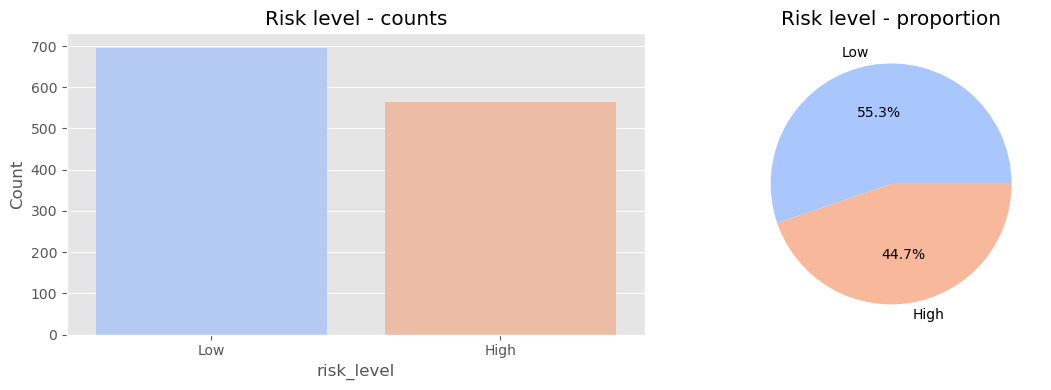

            count   pct
risk_level             
Low           696  55.3
High          563  44.7


In [17]:
risk_counts = df['risk_level'].value_counts().reindex(['Low', 'High'])
risk_pct = (risk_counts / len(df) * 100).round(1)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=risk_counts.index, y=risk_counts.values, ax=axs[0], palette='coolwarm')
axs[0].set_title('Risk level - counts')
axs[0].set_ylabel('Count')

axs[1].pie(risk_counts.values, labels=risk_counts.index, autopct='%1.1f%%',
           colors=sns.color_palette('coolwarm', 2))
axs[1].set_title('Risk level - proportion')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'count': risk_counts, 'pct': risk_pct}))


#### 5.6 Bivariate analysis - features vs. `risk_level`

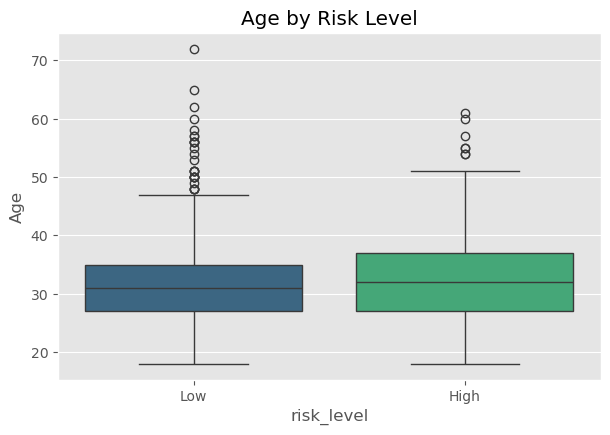

In [18]:
# Age vs risk_level
plt.figure(figsize=(7, 4.5))
sns.boxplot(x='risk_level', y='Age', data=df, order=['Low', 'High'], palette='viridis')
plt.title('Age by Risk Level')
plt.show()

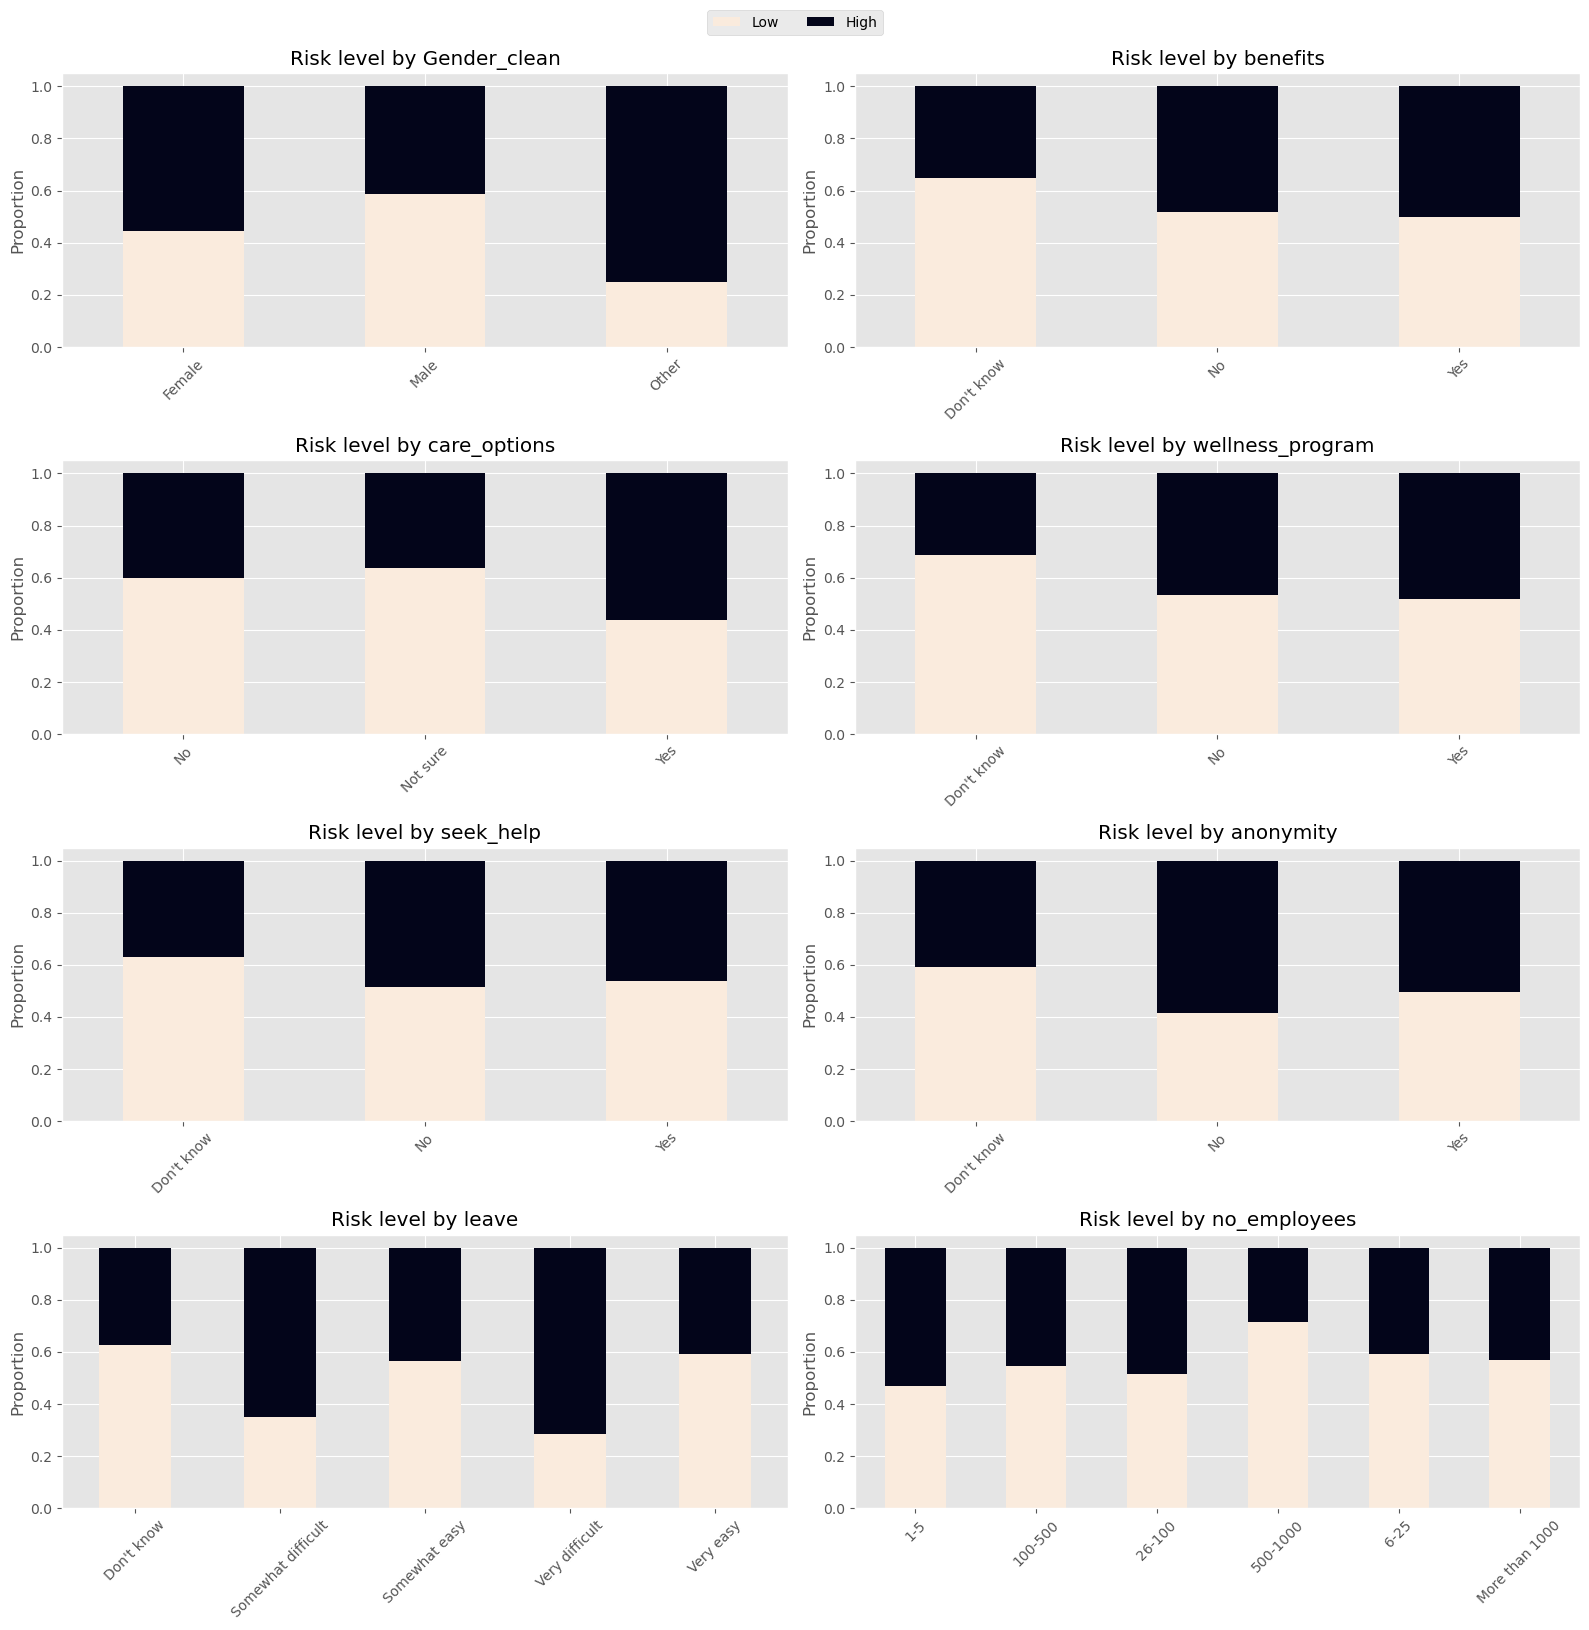

In [19]:
# Workplace-policy categorical features vs risk_level, as normalized (proportion) stacked bars.
# family_history / treatment / work_interfere / obs_consequence are excluded here on purpose -
# they define risk_level itself, so plotting them against it would just re-show the label formula.
bivariate_features = ['Gender_clean', 'benefits', 'care_options', 'wellness_program',
                       'seek_help', 'anonymity', 'leave', 'no_employees']

n_cols = 2
n_rows = int(np.ceil(len(bivariate_features) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 4 * n_rows))
axs = axs.ravel()

for ax, col in zip(axs, bivariate_features):
    ct = pd.crosstab(df[col].fillna('Missing'), df['risk_level'], normalize='index')
    ct = ct[['Low', 'High']]
    ct.plot(kind='bar', stacked=True, ax=ax, colormap='rocket_r', legend=False)
    ax.set_title(f'Risk level by {col}')
    ax.set_xlabel('')
    ax.set_ylabel('Proportion')
    ax.tick_params(axis='x', rotation=45)

for ax in axs[len(bivariate_features):]:
    ax.set_visible(False)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()


These proportions are the closest thing to a "feature vs. target" correlation view available here - most inputs are nominal/ordinal categories rather than numeric, so a standard Pearson correlation matrix (as used in the diabetes project) doesn't apply directly. Section 13's Extra Trees feature importances give a complementary, model-based view of which of these features matter most once combined.

### 6. Feature Set and Leakage Guard

Columns used to construct `risk_level` are excluded from the feature matrix, along with identifiers/free-text/high-missingness columns that don't carry usable signal.

In [20]:
LEAKY_COLUMNS = ['work_interfere', 'family_history', 'treatment', 'obs_consequence']
DROP_COLUMNS = ['Timestamp', 'comments', 'state', 'Gender'] + LEAKY_COLUMNS  # 'Gender' replaced by 'Gender_clean'

feature_df = df.drop(columns=DROP_COLUMNS + ['risk_level'])
target = df['risk_level']

print("Feature columns:", list(feature_df.columns))
print("\nShape:", feature_df.shape)

Feature columns: ['Age', 'Country', 'self_employed', 'no_employees', 'remote_work', 'tech_company', 'benefits', 'care_options', 'wellness_program', 'seek_help', 'anonymity', 'leave', 'mental_health_consequence', 'phys_health_consequence', 'coworkers', 'supervisor', 'mental_health_interview', 'phys_health_interview', 'mental_vs_physical', 'Gender_clean']

Shape: (1259, 20)


### 7. Train/Test Split

This happens **before** any imputer, scaler, or encoder is fit - the test set stays completely untouched until Section 12.


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    feature_df, target,
    test_size=0.2,
    stratify=target,
    random_state=RANDOM_STATE)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(2))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(2))

Train shape: (1007, 20)  Test shape: (252, 20)

Train class balance:
 risk_level
Low     0.55
High    0.45
Name: proportion, dtype: float64

Test class balance:
 risk_level
Low     0.55
High    0.45
Name: proportion, dtype: float64


### 8. Preprocessing Pipeline

All imputation, scaling, and encoding is defined here as a `ColumnTransformer` but not fit yet - it gets fit only when it's wrapped around a model and called with `.fit(X_train, y_train)`, so nothing about the test set (or its distribution) leaks into these transformations.

In [22]:
numeric_features = ['Age']
categorical_features = [c for c in feature_df.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=10))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

y_encoder = LabelEncoder()
y_train_enc = y_encoder.fit_transform(y_train)
y_test_enc = y_encoder.transform(y_test)
print("Label classes:", list(y_encoder.classes_))

Label classes: ['High', 'Low']


### 9. Base Model Building

Each model is wrapped in a `Pipeline` with the shared preprocessor, so cross-validation refits the preprocessor on each fold's training split - no leakage across folds either. `class_weight='balanced'` is used wherever the estimator supports it, given the (mild, by-construction) class imbalance.

In [23]:
def make_pipeline(model):
    return Pipeline(steps=[('preprocess', preprocessor), ('model', model)])

models = {'Logistic Regression': make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)),
          'K-Nearest Neighbor': make_pipeline(KNeighborsClassifier(n_neighbors=12)),
          'Naive Bayes': make_pipeline(BernoulliNB()),
          'Random Forest': make_pipeline(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
          'Extra Trees': make_pipeline(ExtraTreesClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
          'Support Vector Machine': make_pipeline(SVC(probability=True, class_weight='balanced', random_state=RANDOM_STATE)),
          'AdaBoost': make_pipeline(AdaBoostClassifier(random_state=RANDOM_STATE)),
          'Gradient Boosting': make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
          'XGBoost': make_pipeline(XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE)),
          'Neural Net (MLP)': make_pipeline(MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000, early_stopping=True, random_state=RANDOM_STATE)),}

skfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

In [24]:
cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train_enc, cv=skfold, scoring='f1_macro')
    cv_results[name] = scores
    print(f"{name:25s} mean macro-F1: {scores.mean():.4f}  (+/- {scores.std():.4f})")

Logistic Regression       mean macro-F1: 0.6106  (+/- 0.0661)


  File "C:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\DELL\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\DELL\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\DELL\anaconda3\Lib\subprocess.py",

K-Nearest Neighbor        mean macro-F1: 0.6032  (+/- 0.0411)
Naive Bayes               mean macro-F1: 0.5948  (+/- 0.0788)
Random Forest             mean macro-F1: 0.6030  (+/- 0.0529)
Extra Trees               mean macro-F1: 0.6195  (+/- 0.0481)
Support Vector Machine    mean macro-F1: 0.6109  (+/- 0.0542)
AdaBoost                  mean macro-F1: 0.5951  (+/- 0.0785)
Gradient Boosting         mean macro-F1: 0.6037  (+/- 0.0626)
XGBoost                   mean macro-F1: 0.6012  (+/- 0.0255)
Neural Net (MLP)          mean macro-F1: 0.5836  (+/- 0.0512)


In [25]:
table = [[name, scores.mean(), scores.std()] for name, scores in cv_results.items()]
print(tabulate(table, headers=['Model', 'Mean macro-F1 (CV)', 'Std'], tablefmt='rst'))

======================  ====================  =========
Model                     Mean macro-F1 (CV)        Std
======================  ====================  =========
Logistic Regression                 0.610619  0.0660651
K-Nearest Neighbor                  0.603235  0.0410981
Naive Bayes                         0.594821  0.0787805
Random Forest                       0.602968  0.052875
Extra Trees                         0.619491  0.0480693
Support Vector Machine              0.610891  0.0542175
AdaBoost                            0.595134  0.0785304
Gradient Boosting                   0.603709  0.0625948
XGBoost                             0.60121   0.0254593
Neural Net (MLP)                    0.583592  0.0512144
======================  ====================  =========


**Note:** macro-F1 (not accuracy) is still used to select and compare models, since it weighs both risk classes equally regardless of their size - this matters more, not less, once we're down to two classes, since plain accuracy on a roughly-balanced binary target is easy to misread as "good" even when one class is systematically under-predicted. `class_weight='balanced'` is used for Logistic Regression, Random Forest, Extra Trees, and SVM, which support it natively; the median-split construction of `risk_level` keeps the two classes close to 50/50 by design (see the class balance printout in Section 7), so boosting models are left with their defaults rather than adding version-fragile `sample_weight` plumbing through the pipeline for a small, and here largely unnecessary, imbalance correction.

### 10. Hyperparameter Tuning

`GridSearchCV` is run **on the training set only**, with the same 10-fold `StratifiedKFold`, scoring on macro-F1. Grids are kept modest in size to keep runtime reasonable - widen them if you have compute to spare.

In [26]:
tuned_models = {}
tuned_scores = {}

In [27]:
# Logistic Regression

param_lr = {'model__C': [0.01, 0.1, 1, 10, 100],
            'model__penalty': ['l2'],
            'model__solver': ['lbfgs', 'liblinear']}

gs_lr = GridSearchCV(models['Logistic Regression'], param_lr, cv=skfold, scoring='f1_macro', n_jobs=-1)

gs_lr.fit(X_train, y_train_enc)
tuned_models['Logistic Regression'] = gs_lr.best_estimator_
tuned_scores['Logistic Regression'] = gs_lr.best_score_

print(gs_lr.best_params_, gs_lr.best_score_)

{'model__C': 10, 'model__penalty': 'l2', 'model__solver': 'lbfgs'} 0.6112407037502477


In [28]:
# K-Nearest Neighbor

param_knn = {'model__n_neighbors': np.arange(3, 25, 2),
             'model__weights': ['uniform', 'distance'],
             'model__p': [1, 2]}

gs_knn = GridSearchCV(models['K-Nearest Neighbor'], param_knn, cv=skfold, scoring='f1_macro', n_jobs=-1)

gs_knn.fit(X_train, y_train_enc)
tuned_models['K-Nearest Neighbor'] = gs_knn.best_estimator_
tuned_scores['K-Nearest Neighbor'] = gs_knn.best_score_

print(gs_knn.best_params_, gs_knn.best_score_)

{'model__n_neighbors': np.int64(15), 'model__p': 2, 'model__weights': 'distance'} 0.604159782698963


In [29]:
# Random Forest 
param_rf = {'model__n_estimators': [100, 200, 300],
            'model__max_depth': [None, 8, 12],
            'model__max_features': ['sqrt', 'log2']}

gs_rf = GridSearchCV(models['Random Forest'], param_rf, cv=skfold, scoring='f1_macro', n_jobs=-1)

gs_rf.fit(X_train, y_train_enc)
tuned_models['Random Forest'] = gs_rf.best_estimator_
tuned_scores['Random Forest'] = gs_rf.best_score_

print(gs_rf.best_params_, gs_rf.best_score_)

{'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__n_estimators': 200} 0.6261477069642181


In [30]:
# Support Vector Machine
param_svm = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.01, 0.001],
    'model__kernel': ['rbf', 'linear']}

gs_svm = GridSearchCV(models['Support Vector Machine'], param_svm, cv=skfold, scoring='f1_macro', n_jobs=-1)
gs_svm.fit(X_train, y_train_enc)
tuned_models['Support Vector Machine'] = gs_svm.best_estimator_
tuned_scores['Support Vector Machine'] = gs_svm.best_score_

print(gs_svm.best_params_, gs_svm.best_score_)

{'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'} 0.6208798474044008


In [31]:
# AdaBoost
param_ada = {
    'model__n_estimators': [50, 100, 200],
    'model__learning_rate': [0.1, 0.5, 1.0]}

gs_ada = GridSearchCV(models['AdaBoost'], param_ada, cv=skfold, scoring='f1_macro', n_jobs=-1)

gs_ada.fit(X_train, y_train_enc)
tuned_models['AdaBoost'] = gs_ada.best_estimator_
tuned_scores['AdaBoost'] = gs_ada.best_score_

print(gs_ada.best_params_, gs_ada.best_score_)

{'model__learning_rate': 1.0, 'model__n_estimators': 200} 0.6138556849289446


In [32]:
# Gradient Boosting
param_gb = {'model__n_estimators': [100, 200],
            'model__learning_rate': [0.05, 0.1, 0.2],
            'model__max_depth': [2, 3, 4]}

gs_gb = GridSearchCV(models['Gradient Boosting'], param_gb, cv=skfold, scoring='f1_macro', n_jobs=-1)

gs_gb.fit(X_train, y_train_enc)
tuned_models['Gradient Boosting'] = gs_gb.best_estimator_
tuned_scores['Gradient Boosting'] = gs_gb.best_score_

print(gs_gb.best_params_, gs_gb.best_score_)

{'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 100} 0.6162213019845069


In [33]:
# XGBoost
param_xgb = {'model__n_estimators': [100, 200],
             'model__max_depth': [3, 4, 5],
             'model__learning_rate': [0.05, 0.1, 0.2],
             'model__subsample': [0.8, 1.0]}

gs_xgb = GridSearchCV(models['XGBoost'], param_xgb, cv=skfold, scoring='f1_macro', n_jobs=-1)

gs_xgb.fit(X_train, y_train_enc)
tuned_models['XGBoost'] = gs_xgb.best_estimator_
tuned_scores['XGBoost'] = gs_xgb.best_score_

print(gs_xgb.best_params_, gs_xgb.best_score_)

{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 0.8} 0.6137460800322836


Naive Bayes, Extra Trees, and MLP were optimized using GridSearchCV, and their best-performing configurations were retained for final model evaluation.

In [34]:
# Naive Bayes
# BernoulliNB has essentially one real hyperparameter worth tuning (the smoothing prior).

param_nb = {'model__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]}

gs_nb = GridSearchCV(models['Naive Bayes'], param_nb, cv=skfold, scoring='f1_macro', n_jobs=-1)

gs_nb.fit(X_train, y_train_enc)
tuned_models['Naive Bayes'] = gs_nb.best_estimator_
tuned_scores['Naive Bayes'] = gs_nb.best_score_

print(gs_nb.best_params_, gs_nb.best_score_)


{'model__alpha': 0.01} 0.5978196331559669


In [35]:
# Extra Trees
param_et = {'model__n_estimators': [200, 400],
            'model__max_depth': [None, 8, 12],
            'model__max_features': ['sqrt', 'log2']}

gs_et = GridSearchCV(models['Extra Trees'], param_et, cv=skfold, scoring='f1_macro', n_jobs=-1)

gs_et.fit(X_train, y_train_enc)
tuned_models['Extra Trees'] = gs_et.best_estimator_
tuned_scores['Extra Trees'] = gs_et.best_score_

print(gs_et.best_params_, gs_et.best_score_)


{'model__max_depth': 8, 'model__max_features': 'log2', 'model__n_estimators': 400} 0.6262766009979843


In [36]:
# Neural Net (MLP)

param_mlp = {
    'model__hidden_layer_sizes': [(32,), (32, 16), (64, 32)],
    'model__alpha': [1e-4, 1e-3, 1e-2],       # L2 regularization
    'model__learning_rate_init': [1e-3, 1e-2]
}
gs_mlp = GridSearchCV(models['Neural Net (MLP)'], param_mlp, cv=skfold, scoring='f1_macro', n_jobs=-1)
gs_mlp.fit(X_train, y_train_enc)
tuned_models['Neural Net (MLP)'] = gs_mlp.best_estimator_
tuned_scores['Neural Net (MLP)'] = gs_mlp.best_score_
print(gs_mlp.best_params_, gs_mlp.best_score_)


{'model__alpha': 0.0001, 'model__hidden_layer_sizes': (32, 16), 'model__learning_rate_init': 0.01} 0.6106775783321444


In [37]:
table_tuned = [[name, score] for name, score in tuned_scores.items()]

print(tabulate(table_tuned, headers=['Model', 'Best CV macro-F1'], tablefmt='rst'))

======================  ==================
Model                     Best CV macro-F1
======================  ==================
Logistic Regression               0.611241
K-Nearest Neighbor                0.60416
Random Forest                     0.626148
Support Vector Machine            0.62088
AdaBoost                          0.613856
Gradient Boosting                 0.616221
XGBoost                           0.613746
Naive Bayes                       0.59782
Extra Trees                       0.626277
Neural Net (MLP)                  0.610678
======================  ==================


### 11. Final Model Selection

Based on the cross-validation results, the model with the highest macro F1-score was selected as the final model for evaluation. This approach ensures that the final model represents the best-performing classifier while keeping the workflow simple, interpretable, and computationally efficient.

In [38]:
best_model_name = max(tuned_scores, key=tuned_scores.get)
final_model = tuned_models[best_model_name]
print(f"Best model: {best_model_name}  (CV macro-F1: {tuned_scores[best_model_name]:.4f})")


Best model: Extra Trees  (CV macro-F1: 0.6263)


### 12. Final Evaluation - Held-Out Test Set

This is the **only** point in the notebook where the test set is used. Every number below reflects generalization performance, not training performance.

In [39]:
y_pred_test = final_model.predict(X_test)
y_proba_test = final_model.predict_proba(X_test)

print(classification_report(y_test_enc, y_pred_test, target_names=y_encoder.classes_))


              precision    recall  f1-score   support

        High       0.58      0.59      0.59       113
         Low       0.66      0.65      0.66       139

    accuracy                           0.63       252
   macro avg       0.62      0.62      0.62       252
weighted avg       0.63      0.63      0.63       252



#### 12.1 Confusion Matrix (test set)

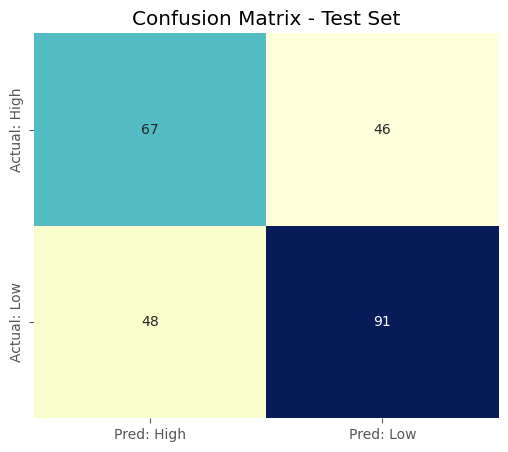

In [40]:
cm = confusion_matrix(y_test_enc, y_pred_test)
cm_df = pd.DataFrame(cm, index=[f"Actual: {c}" for c in y_encoder.classes_],
                      columns=[f"Pred: {c}" for c in y_encoder.classes_])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='YlGnBu', cbar=False)
plt.title('Confusion Matrix - Test Set')
plt.show()

#### 12.2 ROC-AUC (Test Set)


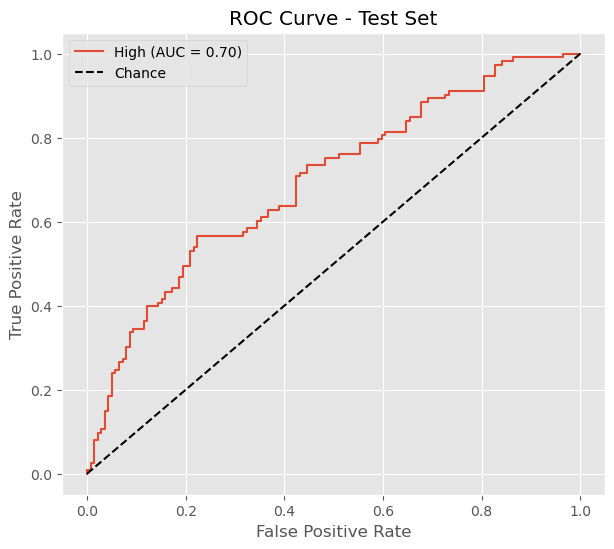

ROC-AUC (High vs Low): 0.6955


In [41]:
# Calculate ROC-AUC using 'High' as the positive class by explicitly binarizing the true labels.
# Identify the encoded label corresponding to the positive ('High') class.

positive_label = 'High'
pos_idx = list(y_encoder.classes_).index(positive_label)

# Convert the true labels into a binary format so ROC-AUC evaluates the intended positive class.

y_true_pos = (y_test_enc == pos_idx).astype(int)

fpr, tpr, _ = roc_curve(y_true_pos, y_proba_test[:, pos_idx])
auc = roc_auc_score(y_true_pos, y_proba_test[:, pos_idx])

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"{positive_label} (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.show()

print(f"ROC-AUC ({positive_label} vs {[c for c in y_encoder.classes_ if c != positive_label][0]}): {auc:.4f}")


#### 12.3 Performance Summary (test set)

In [42]:
summary = [ ['Accuracy', accuracy_score(y_test_enc, y_pred_test)],
            ['Precision (macro)', precision_score(y_test_enc, y_pred_test, average='macro')],
            ['Recall (macro)', recall_score(y_test_enc, y_pred_test, average='macro')],
            ['F1-score (macro)', f1_score(y_test_enc, y_pred_test, average='macro')],
            ['ROC-AUC', auc]]
print(tabulate(summary, headers=['Metric', 'Score'], tablefmt='rst'))


=================  ========
Metric                Score
=================  ========
Accuracy           0.626984
Precision (macro)  0.623421
Recall (macro)     0.623798
F1-score (macro)   0.62357
ROC-AUC            0.695486
=================  ========


### 13. Feature Importance (Interpretability)

The problem statement asks for an interpretable model, not just an accurate one - this pulls feature importances from the tuned Extra Trees model to show which survey questions drive the risk stratification.

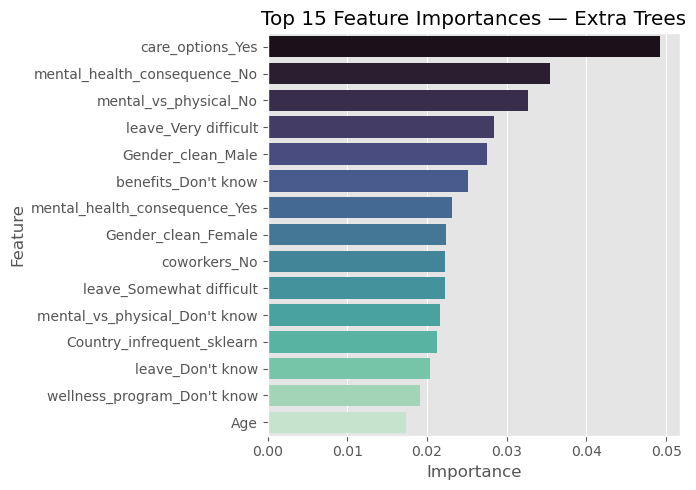

In [43]:
et_pipeline = tuned_models['Extra Trees']

# Extract feature names and corresponding importances
feature_names = (et_pipeline.named_steps['preprocess'].get_feature_names_out())

importances = (et_pipeline.named_steps['model'].feature_importances_)

# Confirm that every transformed feature has an importance value
assert len(feature_names) == len(importances)

importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})

# Clean pipeline-generated prefixes for readability
importance_df['feature'] = (importance_df['feature'].str.replace('num__', '', regex=False).str.replace('cat__', '', regex=False))

# Select the 15 most important features
top_15_features = (importance_df.sort_values('importance', ascending=False).head(15))

# Plotting
plt.figure(figsize=(7, 5))

sns.barplot(data=top_15_features, x='importance', y='feature', palette='mako')

plt.title('Top 15 Feature Importances — Extra Trees')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### 14. Conclusion

- `risk_level` was engineered from `work_interfere`, `family_history`, `treatment`, and `obs_consequence` and binarized at the median into Low/High risk; those four source columns were excluded from the feature set to prevent label leakage, exactly as in the three-class version.
- All preprocessing (imputation, scaling, one-hot encoding) is fit only on the training fold, inside `sklearn.Pipeline` objects - the test set was touched exactly once, for final evaluation.
- Model selection and tuning were driven by **macro-F1**, not accuracy, and `class_weight='balanced'` was applied wherever supported, so a model can't look good just by favoring the majority class.
- The final model is that single best-tuned model, not an ensemble - its held-out test performance is the honest generalization estimate for this project, not the training-set or cross-validation numbers.
- The ROC-AUC calculation was implemented by explicitly defining the positive class and binarizing the target labels before computing the ROC-AUC score, ensuring correct evaluation.
- The model was evaluated using a binary classification approach, where performance metrics such as Accuracy, Precision, Recall, F1-score, and ROC-AUC were computed to assess its ability to distinguish between the two target classes..
- Feature importances point to which workplace factors are most associated with predicted risk level, addressing the "interpretable, highlighting key factors" goal from the problem statement.
